# Traffic forecasting — model report

This notebook starts with **one model's recorded evaluation**. The default is **LightGBM on raw flow**: one global model per target, using the cutoff-aware features from #30. Change `MODEL_RUN` to inspect another LightGBM configuration, Timestral, Chronos-2, or a baseline.

1. Identify the model and its settings.
2. Understand the historical evaluation windows.
3. Read its own errors and measurement coverage.
4. Inspect errors by road/window and, for LightGBM, feature importance.
5. Inspect forecast sources and an observed-versus-forecast example.
6. Optionally compare all recorded models on the same data/windows.
7. Optionally rerun just the selected model.

The shared journal contains the scores. Hourly predictions, feature importances and plots are local artifacts. Missing local files do not prevent reading the scores. Comparisons and fresh execution are off by default. Historical results do not constitute the final competition submission or select its model.


## 1. Which model am I looking at?

Change `MODEL_RUN` to select a recorded run. LightGBM starts with `lightgbm_raw`; `lightgbm_deep` is the best pooled flow run among the six settings tried. The model card and scores below describe only the selected run.


In [1]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").exists(), "Open from the repository root or notebooks folder."

MODEL_RUN = "lightgbm_raw"
SNAPSHOT = "9e714afe6479d9a22e680b0e70893e06fd04c574219a2ec28f9ceffb237c391d"
WINDOW_CUTOFF = "2026-10-22"
EXAMPLE_ROAD = "Convention"
ARTIFACT_DIR = ROOT / "outputs/metrics" / (
    "lightgbm_20261101" if MODEL_RUN.startswith("lightgbm_") else "timestral_20261101"
)

SHOW_COMPARISONS = False
RERUN_MODEL = False


In [2]:
MODEL_NAMES = {
    "baseline_previous_week": "Previous-week baseline",
    "baseline_four_week": "Four-week mean baseline",
    "baseline_day_type": "Day-type profile baseline",
    "baseline_holiday_aware": "Holiday-aware baseline",
    "chronos_history": "Chronos-2 — traffic history",
    "chronos_calendar": "Chronos-2 — history + calendar",
    "chronos_retained_multivariate": "Chronos-2 — history + calendar, joint targets",
    "timestral_5m_history": "Timestral-5M — traffic history",
    "timestral_5m_calendar": "Timestral-5M — history + calendar",
    "timestral_5m_calendar_multivariate": "Timestral-5M — history + calendar, joint targets",
    "timestral_28m_calendar": "Timestral-28M — history + calendar",
    "timestral_28m_calendar_multivariate": "Timestral-28M — history + calendar, joint targets",
}
MODEL_NAMES.update({
    "lightgbm_raw": "LightGBM — raw flow, 200 trees / depth 6",
    "lightgbm_log": "LightGBM — log1p flow, 200 trees / depth 6",
    "lightgbm_shallow": "LightGBM — raw flow, 100 trees / depth 3",
    "lightgbm_shallow_log": "LightGBM — log1p flow, 100 trees / depth 3",
    "lightgbm_deep": "LightGBM — raw flow, 400 trees / depth 8",
    "lightgbm_deep_log": "LightGBM — log1p flow, 400 trees / depth 8",
})
TARGET_NAMES = {"debit_horaire": "Traffic flow", "taux_occupation": "Occupancy"}
TARGET_UNITS = {"debit_horaire": "vehicles/hour", "taux_occupation": "percentage points"}

journal = pd.read_csv(ROOT / "docs/experiments.csv")
recorded = journal.loc[journal.description.str.match(r"Issue #(?:20|31);", na=False)].copy()
recorded["fingerprint"] = recorded.description.str.extract(r"fingerprint\s+([0-9a-f]{64})", expand=False)
recorded = recorded.loc[recorded.fingerprint.eq(SNAPSHOT)]
recorded["run"] = recorded.description.str.extract(r"Issue #(?:20|31);\s*([^;]+);", expand=False)
recorded = recorded.drop_duplicates("run", keep="last")
assert MODEL_RUN in set(recorded.run), f"Choose a recorded run from {list(recorded.run)}"
selected_record = recorded.set_index("run").loc[MODEL_RUN]
all_scores = pd.concat([
    pd.DataFrame(json.loads(row.scores)["scores"]).assign(run=row.run)
    for row in recorded.itertuples(index=False)
], ignore_index=True)
all_scores["cutoff"] = pd.to_datetime(all_scores.cutoff)
model_scores = all_scores.loc[all_scores.run.eq(MODEL_RUN)].copy()
window_dates = pd.DatetimeIndex(model_scores.cutoff.unique()).sort_values()
window = pd.Timestamp(WINDOW_CUTOFF)
assert window in window_dates, "Choose a cutoff listed in section 2."
is_foundation = selected_record.model in {"TimestralForecaster", "Chronos2Forecaster"}

def summarize_scores(frame, groups):
    """Pool squared errors over valid observations; retain missing-truth counts."""
    frame = frame.assign(squared_error=frame.rmse.pow(2) * frame.n_scored)
    result = frame.groupby([*groups, "variable"], sort=False).agg(
        squared_error=("squared_error", "sum"),
        expected=("n_expected", "sum"), scored=("n_scored", "sum"), ignored=("n_ignored", "sum"),
    ).reset_index()
    result["rmse"] = np.sqrt(result.squared_error / result.scored.replace(0, np.nan))
    result["coverage"] = 100 * result.scored / result.expected.replace(0, np.nan)
    return result

def score_table(frame, groups=()):
    """Friendly display only: raw scores keep numerical NaN for unscored groups."""
    result = frame[[*groups, "variable", "rmse", "scored", "ignored", "coverage"]].copy()
    result["variable"] = result.variable.map(TARGET_NAMES)
    result["Unit"] = frame.variable.map(TARGET_UNITS)
    result["rmse"] = result.rmse.map(lambda value: "Not scored" if pd.isna(value) else f"{value:.3f}")
    result["coverage"] = result.coverage.round(1)
    result["Status"] = np.where(result.scored.eq(0), "No valid measurements", "Scored")
    return result.rename(columns={
        "arc": "Road", "variable": "Target", "rmse": "RMSE",
        "scored": "Scored hours", "ignored": "Unscored hours",
        "coverage": "Coverage (%)",
    })

def saved_seconds(description, field):
    match = re.search(rf"{field}\s+([0-9.]+)s", description)
    return float(match.group(1)) if match else None

is_lightgbm = selected_record.model == "LightGBMForecaster"


In [3]:
context = re.search(r"context\s+([0-9]+)\s+h", selected_record.description)
settings = {
    "Selected model": MODEL_NAMES.get(MODEL_RUN, MODEL_RUN),
    "Model type": ("Global gradient boosting" if is_lightgbm else
                   "Pretrained forecasting model" if is_foundation else "Rule-based baseline"),
    "Inputs": ("27 tabular features; calendar, weekly traffic lags/profiles, lagged weather" if is_lightgbm else
               "Past traffic + calendar" if "calendar" in MODEL_RUN else "Past traffic and rule-specific calendar use"),
    "Targets": ("Flow and occupancy separately" if is_lightgbm else
                ("Flow and occupancy jointly" if "multivariate" in MODEL_RUN else
                 "Flow and occupancy separately") if is_foundation else "Flow and occupancy"),
    "Maximum history": ("All cutoff-limited measured history" if is_lightgbm else
                        f"{int(context.group(1)):,} hours" if context else "Defined by the baseline rule"),
    "Recorded at (UTC)": selected_record.date,
    "Dataset": SNAPSHOT[:8],
    "View": "Saved evaluation results",
}
if is_lightgbm:
    recorded_parameters = re.search(r"parameters (\{.*?\});", selected_record.description)
    assert recorded_parameters, "Stored LightGBM parameters are missing."
    parameters = json.loads(recorded_parameters.group(1))
    settings["Trees / maximum depth / learning rate"] = (
        f"{parameters['n_estimators']} / {parameters['max_depth']} / {parameters['learning_rate']}"
    )
    settings["Flow training target"] = ("log1p(flow), inverted before scoring" if "flow=log1p;" in selected_record.description
                                       else "Raw flow")
    settings["Outage fallback"] = "Holiday-aware baseline if fewer than 168 valid hours in the last 28 days"
display(pd.DataFrame(settings.items(), columns=["Setting", "Value"]))


,Setting,Value
0,Selected model,"LightGBM — raw flow, 200 trees / depth 6"
1,Model type,Global gradient boosting
2,Inputs,"27 tabular features; calendar, weekly traffic ..."
3,Targets,Flow and occupancy separately
4,Maximum history,All cutoff-limited measured history
5,Recorded at (UTC),2026-11-01T18:01:47.384493+00:00
6,Dataset,9e714afe
7,View,Saved evaluation results
8,Trees / maximum depth / learning rate,200 / 6 / 0.05
9,Flow training target,Raw flow


## 2. How was this model evaluated?

We replay **eight historical forecasting situations**. For each one:

1. The model receives observations through **Thursday 23:00**.
2. It forecasts **144 hours**: Friday plus Saturday–Wednesday.
3. The **120 Saturday–Wednesday hours per road** are scored against valid measurements.

The three official roads are Champs-Elysées, Convention and Saint-Pères. Missing or invalid truth is excluded and counted. The dataset covers January 2024–October 30, 2026. These historical evaluations support the model choice for the November 7–11 submission.

LightGBM predicts the 120 target hours directly. Its models and feature statistics are refitted inside every window; no evaluation labels are used for fitting or early stopping. The six tuning runs reuse these windows, so they are development comparisons, not an untouched final holdout.


In [4]:
evaluation_windows = pd.DataFrame({
    "History available through": window_dates + pd.Timedelta(hours=23),
    "Forecast begins (Friday)": window_dates + pd.Timedelta(days=1),
    "Scoring begins (Saturday)": window_dates + pd.Timedelta(days=2),
    "Scoring ends (Wednesday)": window_dates + pd.Timedelta(days=6, hours=23),
    "Scored hours per road": 120,
})
for column in evaluation_windows.columns[:-1]:
    evaluation_windows[column] = evaluation_windows[column].dt.strftime("%Y-%m-%d %H:%M")
display(evaluation_windows)


,History available through,Forecast begins (Friday),Scoring begins (Saturday),Scoring ends (Wednesday),Scored hours per road
0,2024-11-07 23:00,2024-11-08 00:00,2024-11-09 00:00,2024-11-13 23:00,120
1,2024-12-19 23:00,2024-12-20 00:00,2024-12-21 00:00,2024-12-25 23:00,120
2,2024-12-26 23:00,2024-12-27 00:00,2024-12-28 00:00,2025-01-01 23:00,120
3,2025-04-17 23:00,2025-04-18 00:00,2025-04-19 00:00,2025-04-23 23:00,120
4,2025-07-10 23:00,2025-07-11 00:00,2025-07-12 00:00,2025-07-16 23:00,120
5,2025-10-16 23:00,2025-10-17 00:00,2025-10-18 00:00,2025-10-22 23:00,120
6,2025-11-06 23:00,2025-11-07 00:00,2025-11-08 00:00,2025-11-12 23:00,120
7,2026-10-22 23:00,2026-10-23 00:00,2026-10-24 00:00,2026-10-28 23:00,120


## 3. The selected model's own statistics

**This section reports only the selected model, across all three official roads.** Its documented baseline fallback is included when sensors provide insufficient recent history.

- **RMSE:** prediction error; lower is better. Flow uses vehicles/hour, occupancy uses percentage points.
- **Scored hours:** road/hour observations with valid ground truth.
- **Unscored hours:** predictions that could not be scored.
- **Coverage:** the fraction of expected observations that could be scored.

RMSE is pooled over valid observations: `sqrt(sum(n_scored × RMSE²) / sum(n_scored))`. The second table isolates weekends and public holidays.


In [5]:
overall = summarize_scores(model_scores.loc[model_scores.subset.eq("all")], [])
print(MODEL_NAMES.get(MODEL_RUN, MODEL_RUN))
print("All scored hours — three official roads")
display(score_table(overall))

atypical = summarize_scores(model_scores.loc[model_scores.subset.eq("atypical")], [])
print("Weekends and public holidays only — three official roads")
display(score_table(atypical))

elapsed = saved_seconds(selected_record.description, "backtest")
loading = saved_seconds(selected_record.description, "loading")
if elapsed is not None:
    print(f"Recorded evaluation time: {elapsed:.1f} seconds for all {len(window_dates)} windows.")
if loading is not None:
    print(f"Weight loading, measured separately: {loading:.3f} seconds.")


LightGBM — raw flow, 200 trees / depth 6
All scored hours — three official roads


,Target,RMSE,Scored hours,Unscored hours,Coverage (%),Unit,Status
0,Traffic flow,127.382,1684,1196,58.5,vehicles/hour,Scored
1,Occupancy,3.970,1684,1196,58.5,percentage points,Scored


Weekends and public holidays only — three official roads


,Target,RMSE,Scored hours,Unscored hours,Coverage (%),Unit,Status
0,Traffic flow,127.599,972,612,61.4,vehicles/hour,Scored
1,Occupancy,4.203,972,612,61.4,percentage points,Scored


Recorded evaluation time: 10.0 seconds for all 8 windows.


## 4. Where does the model make errors?

The first table groups the selected model's errors by road across all eight windows. The next table inspects the window chosen with `WINDOW_CUTOFF`.

**“Not scored” means there were no valid measurements to assess that row.** The model can still have produced forecasts; they are shown in section 5. A missing score is kept separate from a zero error.


In [6]:
per_road = summarize_scores(model_scores.loc[model_scores.subset.eq("all")], ["arc"])
display(score_table(per_road, ["arc"]))

window_scores = model_scores.loc[model_scores.cutoff.eq(window) & model_scores.subset.eq("all")]
window_report = summarize_scores(window_scores, ["arc"])
print(f"Selected window: cutoff {window:%Y-%m-%d}; scored {(window + pd.Timedelta(days=2)):%Y-%m-%d} "
      f"through {(window + pd.Timedelta(days=6)):%Y-%m-%d}")
display(score_table(window_report, ["arc"]))


,Road,Target,RMSE,Scored hours,Unscored hours,Coverage (%),Unit,Status
0,Champs-Elysées,Traffic flow,167.709,690,270,71.9,vehicles/hour,Scored
1,Champs-Elysées,Occupancy,5.701,690,270,71.9,percentage points,Scored
2,Convention,Traffic flow,84.682,659,301,68.6,vehicles/hour,Scored
3,Convention,Occupancy,2.034,659,301,68.6,percentage points,Scored
4,Saint-Pères,Traffic flow,97.614,335,625,34.9,vehicles/hour,Scored
5,Saint-Pères,Occupancy,2.040,335,625,34.9,percentage points,Scored


Selected window: cutoff 2026-10-22; scored 2026-10-24 through 2026-10-28


,Road,Target,RMSE,Scored hours,Unscored hours,Coverage (%),Unit,Status
0,Champs-Elysées,Traffic flow,Not scored,0,120,0.0,vehicles/hour,No valid measurements
1,Champs-Elysées,Occupancy,Not scored,0,120,0.0,percentage points,No valid measurements
2,Convention,Traffic flow,53.557,97,23,80.8,vehicles/hour,Scored
3,Convention,Occupancy,1.008,97,23,80.8,percentage points,Scored
4,Saint-Pères,Traffic flow,130.587,96,24,80.0,vehicles/hour,Scored
5,Saint-Pères,Occupancy,2.071,96,24,80.0,percentage points,Scored


### Which features does LightGBM use?

Gain importance measures training loss reduction. Normalize within each target/window, then average across windows; raw gain scales cannot be compared between flow, log-flow, and occupancy. This is descriptive model behaviour, not a causal effect or a held-out permutation score.


In [7]:
if is_lightgbm:
    importance_path = ARTIFACT_DIR / f"{MODEL_RUN}_importance.csv"
    if importance_path.exists():
        importance = pd.read_csv(importance_path)
        total_gain = importance.groupby(["cutoff", "variable"]).gain.transform("sum")
        importance["gain_share"] = 100 * importance.gain / total_gain.replace(0, np.nan)
        ranked = importance.groupby(["variable", "feature"], as_index=False).agg(
            mean_gain_percent=("gain_share", "mean"), mean_splits=("split", "mean")
        ).sort_values(["variable", "mean_gain_percent"], ascending=[True, False])
        display(ranked.groupby("variable", sort=False).head(10).round(2))
    else:
        print("Local feature-importance file is absent; recorded model scores remain available.")
else:
    print("Feature importance applies to the LightGBM runs. Select one in section 1 to inspect it.")


,variable,feature,mean_gain_percent,mean_splits
7,debit_horaire,debit_horaire_profile,69.99,516.50
3,debit_horaire,debit_horaire_lag_168h,13.89,508.50
4,debit_horaire,debit_horaire_lag_336h,2.40,328.75
19,debit_horaire,profile_count,2.03,534.88
16,debit_horaire,month_cos,2.01,263.50
24,debit_horaire,taux_occupation_profile,1.24,176.62
0,debit_horaire,arc,1.12,169.88
6,debit_horaire,debit_horaire_lag_672h,1.10,255.62
5,debit_horaire,debit_horaire_lag_504h,0.86,284.25
9,debit_horaire,hour_sin,0.86,178.12


## 5. What did the model actually predict?

This section reads the saved hourly predictions for the selected run. It shows:

- how many forecasts came from the pretrained model and how many used a baseline fallback;
- a short example for `EXAMPLE_ROAD` in the selected window;
- observed and forecast traffic curves when the matching local dataset is available.

A foundation model uses the holiday-aware baseline when an arc has fewer than 168 valid hours in the retained context's last 28 days. The scores above include this mixture. Local prediction files, raw data and weights are kept outside Git; scores remain readable if those files are absent.


In [8]:
predictions = pd.DataFrame()
prediction_path = ARTIFACT_DIR / f"{MODEL_RUN}_predictions.parquet"
manifest_path = ARTIFACT_DIR / "dataset_manifest.json"
if prediction_path.exists() and manifest_path.exists():
    artifact_manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    if artifact_manifest["fingerprint"] == SNAPSHOT:
        predictions = pd.read_parquet(prediction_path)
    else:
        print("Choose an artifact folder with the selected dataset fingerprint.")
else:
    print("Local prediction files are absent. Scores above remain available from the journal.")

if not predictions.empty:
    print(f"{len(predictions):,} forecasts across {predictions.cutoff.nunique()} windows.")
    if is_foundation or is_lightgbm:
        origins = np.where(predictions.forecast_source.str.startswith("fallback_"),
                           "Baseline fallback", "LightGBM" if is_lightgbm else "Pretrained model")
    else:
        origins = pd.Series("Baseline rules", index=predictions.index)
    source_counts = pd.crosstab(predictions.arc, origins).rename_axis(index="Road", columns=None)
    source_counts["Total forecast hours"] = source_counts.sum(axis=1)
    display(source_counts)


2,880 forecasts across 8 windows.


,Baseline fallback,LightGBM,Total forecast hours
Road,,,
Champs-Elysées,120,840,960
Convention,240,720,960
Saint-Pères,600,360,960


In [9]:
example = pd.DataFrame()
has_observations = False
if not predictions.empty:
    example = predictions.loc[
        predictions.cutoff.eq(window) & predictions.arc.eq(EXAMPLE_ROAD)
    ].sort_values("datetime").copy()
    assert not example.empty, "Choose a road present in the saved forecasts."
    data_dir = ROOT / "data/processed/dataset"
    if (data_dir / "dataset.parquet").exists() and (data_dir / "_manifest.json").exists():
        local_manifest = json.loads((data_dir / "_manifest.json").read_text(encoding="utf-8"))
        if local_manifest["fingerprint"] == SNAPSHOT:
            from traffic_prediction.data.dataset import content_sha256

            observations = pd.read_parquet(data_dir / "dataset.parquet")
            assert content_sha256(observations) == local_manifest["content_sha256"]["dataset.parquet"], "Dataset changed."
            observations = observations.loc[
                observations.arc.eq(EXAMPLE_ROAD),
                ["datetime", "debit_horaire", "taux_occupation", "qualite_mesure"],
            ].copy()
            observations.loc[observations.qualite_mesure.ne("ok"),
                             ["debit_horaire", "taux_occupation"]] = np.nan
            observations = observations.rename(columns={
                "debit_horaire": "actual_flow", "taux_occupation": "actual_occupancy",
            })
            example = example.merge(observations, on="datetime", how="left", validate="one_to_one")
            has_observations = True
    columns = ["datetime", "debit_horaire", "taux_occupation"]
    if has_observations:
        columns += ["actual_flow", "actual_occupancy"]
    columns += ["forecast_source"]
    preview = example[columns].head(10).round(3).rename(columns={
        "datetime": "Hour", "debit_horaire": "Predicted flow (veh/h)",
        "taux_occupation": "Predicted occupancy (%)", "actual_flow": "Observed flow (veh/h)",
        "actual_occupancy": "Observed occupancy (%)", "forecast_source": "Prediction source",
    })
    preview = preview.astype(object).where(preview.notna(), "Missing measurement")
    print(f"{EXAMPLE_ROAD} — selected historical window")
    display(preview)
    if not has_observations:
        print("Observed values require the matching local dataset.")


Convention — selected historical window


,Hour,Predicted flow (veh/h),Predicted occupancy (%),Observed flow (veh/h),Observed occupancy (%),Prediction source
0,2026-10-24 00:00:00,357.923,2.364,366.0,2.318,lightgbm
1,2026-10-24 01:00:00,302.64,1.96,326.0,2.332,lightgbm
2,2026-10-24 02:00:00,232.947,1.209,214.0,1.435,lightgbm
3,2026-10-24 03:00:00,208.825,1.121,177.0,1.279,lightgbm
4,2026-10-24 04:00:00,149.764,0.792,141.0,1.067,lightgbm
5,2026-10-24 05:00:00,151.898,0.717,125.0,1.557,lightgbm
6,2026-10-24 06:00:00,142.037,0.67,123.0,0.802,lightgbm
7,2026-10-24 07:00:00,170.044,1.038,170.0,1.353,lightgbm
8,2026-10-24 08:00:00,228.028,1.511,197.0,1.722,lightgbm
9,2026-10-24 09:00:00,314.898,2.032,277.0,2.116,lightgbm


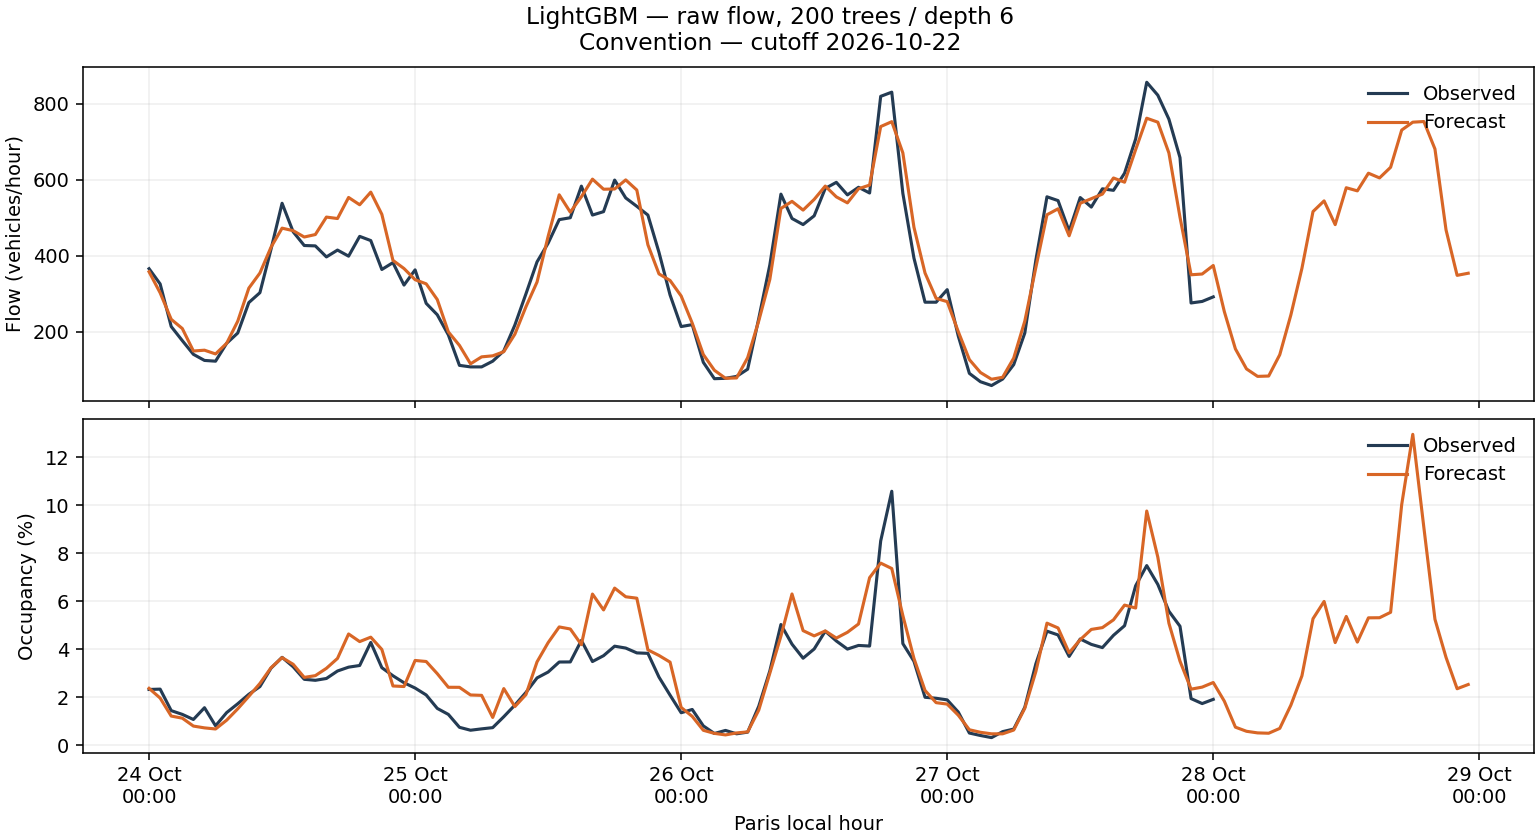

Gaps in the observed curve represent unscored measurements.


In [10]:
if not example.empty and has_observations:
    import importlib.util

    if importlib.util.find_spec("matplotlib") is not None:
        import matplotlib.dates as mdates
        import matplotlib.pyplot as plt

        fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, layout="constrained")
        for axis, predicted, actual, unit in [
            (axes[0], "debit_horaire", "actual_flow", "Flow (vehicles/hour)"),
            (axes[1], "taux_occupation", "actual_occupancy", "Occupancy (%)"),
        ]:
            if example[actual].notna().any():
                axis.plot(example.datetime, example[actual], color="#243b53", label="Observed", linewidth=1.6)
            axis.plot(example.datetime, example[predicted], color="#d86626", label="Forecast", linewidth=1.6)
            axis.set_ylabel(unit)
            axis.grid(alpha=0.2)
            axis.legend(loc="upper right", frameon=False)
        axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
        axes[1].set_xlabel("Paris local hour")
        fig.suptitle(f"{MODEL_NAMES.get(MODEL_RUN, MODEL_RUN)}\n{EXAMPLE_ROAD} — cutoff {window:%Y-%m-%d}")
        figure_path = ROOT / "outputs/figures" / f"{MODEL_RUN}_{EXAMPLE_ROAD}_{window:%Y%m%d}.png"
        figure_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(figure_path, dpi=140, facecolor="white")
        plt.close(fig)
        display(Image(filename=str(figure_path)))
        if example[["actual_flow", "actual_occupancy"]].notna().any().any():
            print("Gaps in the observed curve represent unscored measurements.")
        else:
            print("This window has no valid observations; the plot shows the saved forecasts.")
    else:
        print("The optional plot uses the Matplotlib version in requirements.txt.")


## 6. Optional: compare this model with the others

Set `SHOW_COMPARISONS = True` in section 1 to display the saved runs on the same dataset and windows: four baselines, three Chronos-2 variants, five Timestral variants and six LightGBM settings. The table pools squared errors over valid observations on all three official roads. Flow and occupancy have different units and remain separate.

Raw-flow LightGBM improved flow in these development backtests; `log1p` did not. Occupancy still favours a foundation model. The final model or ensemble remains issue #32.


In [11]:
if SHOW_COMPARISONS:
    cutoff_sets = all_scores.groupby("run").cutoff.agg(lambda values: frozenset(values))
    assert cutoff_sets.nunique() == 1, "Compare runs with matching evaluation windows."
    comparison_scores = summarize_scores(all_scores.loc[all_scores.subset.eq("all")], ["run"])
    comparison_table = comparison_scores.pivot(index="run", columns="variable", values="rmse").rename(
        columns={"debit_horaire": "Flow RMSE (veh/h)", "taux_occupation": "Occupancy RMSE (points)"}
    )
    comparison_table.index = comparison_table.index.map(lambda label: MODEL_NAMES.get(label, label))
    comparison_table.index.name = "Model"
    display(comparison_table.round(3))
else:
    print(f"{len(recorded)} evaluated runs are available. This view focuses on the selected model.")


18 evaluated runs are available. This view focuses on the selected model.


## 7. Optional: run this model again

Set `RERUN_MODEL = True` in section 1 to rerun **only `MODEL_RUN`** on the current local dataset and the shared backtest windows. A pretrained model performs fresh inference; it does not train a new network here.

Prepare local data and dependencies using the README first. Pretrained models also need their cached weights; LightGBM refits two regressors from the supplied history. This step runs offline, creates a new dated folder, saves scores and hourly forecasts, and appends the experiment to `docs/experiments.csv`. The helper cell below is collapsed because it implements saving rather than interpreting results.

After a fresh run, keep `RERUN_MODEL = False` when reading reports. If the dataset changed, use the newly printed fingerprint as `SNAPSHOT` to inspect that saved run in sections 1–6.


In [12]:
def run_and_save(label, model, data, manifest, output_dir, journal_path, author=None):
    """Record scores and aligned hourly forecasts from the common backtest."""
    import getpass
    import time
    from traffic_prediction import evaluate

    records, importance_records = [], []
    original_predict = model.predict

    def capture(history, target_times):
        table = original_predict(history, target_times)
        saved = table.copy()
        saved.insert(0, "cutoff", history.datetime.max().normalize())
        trace = getattr(model, "sources_", None)
        if trace is not None:
            index = pd.MultiIndex.from_frame(table[evaluate.KEYS])
            saved["forecast_source"] = trace.reindex(index).to_numpy()
        records.append(saved)
        importance = getattr(model, "feature_importances_", pd.DataFrame())
        if not importance.empty:
            importance_records.append(importance.assign(cutoff=history.datetime.max().normalize()))
        return table

    loading = 0.0
    if hasattr(model, "_pipeline"):
        started = time.perf_counter()
        model._pipeline()
        loading = time.perf_counter() - started
    cutoffs = evaluate.load_cutoffs()
    model.predict = capture
    started = time.perf_counter()
    try:
        result = evaluate.backtest(model, data, cutoffs, experiments_path=None)
    finally:
        del model.predict
    elapsed = time.perf_counter() - started

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    pd.concat(records, ignore_index=True).to_parquet(
        output_dir / f"{label}_predictions.parquet", index=False, compression="zstd"
    )
    for name in ["scores", "per_arc", "summary"]:
        getattr(result, name).to_csv(output_dir / f"{label}_{name}.csv", index=False)
    if importance_records:
        pd.concat(importance_records, ignore_index=True).to_csv(output_dir / f"{label}_importance.csv", index=False)
    settings = model.describe() if hasattr(model, "describe") else type(model).__name__
    metadata = {
        "run": label, "model": type(model).__name__, "settings": settings,
        "dataset_fingerprint": manifest["fingerprint"],
        "cutoffs": [str(day.date()) for day in cutoffs],
        "loading_seconds": loading, "backtest_seconds": elapsed,
    }
    (output_dir / f"{label}_run.json").write_text(
        json.dumps(metadata, indent=2) + "\n", encoding="utf-8"
    )
    description = (
        f"Issue #{31 if type(model).__name__ == 'LightGBMForecaster' else 20}; {label}; {settings}; fingerprint {manifest['fingerprint']}; "
        f"{len(cutoffs)} shared cutoffs; loading {loading:.3f}s; backtest {elapsed:.3f}s; "
        f"hourly predictions: {output_dir.name}/{label}_predictions.parquet"
    )
    evaluate._append_experiment(result, Path(journal_path), author or getpass.getuser(), type(model).__name__, description)
    return result


In [13]:
if RERUN_MODEL:
    import os
    import platform
    import subprocess
    import sys
    from datetime import datetime, timezone

    os.environ["HF_HUB_OFFLINE"] = "1"
    os.environ["HF_HUB_CACHE"] = str(ROOT / "models/huggingface")
    os.environ["HF_HOME"] = str(ROOT / "models/hf-home")
    torch_version, torch_threads, cuda_available = None, None, False
    if is_foundation:
        import torch

        torch.set_num_threads(min(6, torch.get_num_threads()))
        torch_version = torch.__version__
        torch_threads = torch.get_num_threads()
        cuda_available = torch.cuda.is_available()
    from traffic_prediction.data.dataset import content_sha256
    from traffic_prediction.data.traffic import file_sha256
    from traffic_prediction.models.baselines import (
        PreviousWeekBaseline, FourWeekMeanBaseline,
        DayTypeProfileBaseline, HolidayAwarePreviousWeekBaseline,
    )
    from traffic_prediction.models.chronos import Chronos2Forecaster
    from traffic_prediction.models.timestral import TimestralForecaster
    from traffic_prediction.train import LIGHTGBM_RUNS, LightGBMForecaster

    dataset_dir = ROOT / "data/processed/dataset"
    manifest = json.loads((dataset_dir / "_manifest.json").read_text(encoding="utf-8"))
    data = pd.read_parquet(dataset_dir / "dataset.parquet")
    calendar_path = ROOT / "data/processed/calendar/calendar.parquet"
    calendar = pd.read_parquet(calendar_path)
    assert content_sha256(data) == manifest["content_sha256"]["dataset.parquet"], "Dataset changed."
    assert file_sha256(calendar_path) == manifest["inputs_sha256"]["calendar"], "Calendar changed."

    factories = {
        "baseline_previous_week": lambda: PreviousWeekBaseline(calendar),
        "baseline_four_week": lambda: FourWeekMeanBaseline(calendar),
        "baseline_day_type": lambda: DayTypeProfileBaseline(calendar),
        "baseline_holiday_aware": lambda: HolidayAwarePreviousWeekBaseline(calendar),
        "chronos_history": lambda: Chronos2Forecaster(calendar, calendar_covariates=(), multivariate=False),
        "chronos_calendar": lambda: Chronos2Forecaster(calendar, multivariate=False),
        "chronos_retained_multivariate": lambda: Chronos2Forecaster(calendar),
        "timestral_5m_history": lambda: TimestralForecaster(calendar, model_size="5M", context_hours=8192, multivariate=False, calendar_covariates=()),
        "timestral_5m_calendar": lambda: TimestralForecaster(calendar, model_size="5M", context_hours=8192, multivariate=False),
        "timestral_5m_calendar_multivariate": lambda: TimestralForecaster(calendar, model_size="5M", context_hours=8192, multivariate=True),
        "timestral_28m_calendar": lambda: TimestralForecaster(calendar, model_size="28M", context_hours=8192, multivariate=False),
        "timestral_28m_calendar_multivariate": lambda: TimestralForecaster(calendar, model_size="28M", context_hours=8192, multivariate=True),
    }
    if is_lightgbm:
        covariates = pd.read_parquet(dataset_dir / "covariates.parquet")
        assert content_sha256(covariates) == manifest["content_sha256"]["covariates.parquet"], "Covariates changed."
        factories.update({label: lambda options=options: LightGBMForecaster(covariates, **options)
                          for label, options in LIGHTGBM_RUNS.items()})
    assert MODEL_RUN in factories, "Choose a configured model from factories."
    timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    output_dir = ROOT / "outputs/metrics" / f"model_{timestamp}"
    output_dir.mkdir(parents=True, exist_ok=False)
    (output_dir / "environment.txt").write_text(
        subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True), encoding="utf-8"
    )
    (output_dir / "dataset_manifest.json").write_text(
        json.dumps(manifest, indent=2) + "\n", encoding="utf-8"
    )
    runtime = {"python": platform.python_version(), "platform": platform.platform(),
               "torch": torch_version, "torch_threads": torch_threads,
               "cuda_available": cuda_available,
               "lightgbm": __import__("importlib.metadata", fromlist=["version"]).version("lightgbm") if is_lightgbm else None}
    (output_dir / "runtime.json").write_text(
        json.dumps(runtime, indent=2) + "\n", encoding="utf-8"
    )
    print({"output": str(output_dir), **runtime})
    result = run_and_save(MODEL_RUN, factories[MODEL_RUN](), data, manifest, output_dir,
                          ROOT / "docs/experiments.csv")
    print("Fresh run saved for:", MODEL_NAMES.get(MODEL_RUN, MODEL_RUN))
    print("Dataset fingerprint:", manifest["fingerprint"])
    fresh = result.scores.loc[result.scores.subset.eq("all")]
    display(score_table(summarize_scores(fresh, [])))
else:
    print("Fresh inference is off. Sections 1–5 show the model evaluation already performed and saved.")


Fresh inference is off. Sections 1–5 show the model evaluation already performed and saved.


## Where are the results kept?

| File | Use |
|---|---|
| `docs/experiments.csv` | Shared, versioned scores, settings, timings and dataset fingerprints. |
| `outputs/metrics/timestral_20261101/` | Local original scores, hourly predictions, weight/environment verification and audit. |
| `outputs/metrics/model_<timestamp>/` | Outputs from a fresh run in section 7. |
| `outputs/figures/` | Exportable observed-versus-forecast plots. |

Keep scores and this notebook in Git. Keep raw data, weights and generated evaluation artifacts outside Git; share the small evaluation bundle separately when the team needs the hourly predictions for ensembles.

LightGBM's six runs additionally save per-window gain/split importance and training/fallback counts under `outputs/metrics/lightgbm_20261101/`. The shared journal contains their complete scores and settings; local artifacts provide the hourly detail for #32.
